Forma del dataset: (284807, 31)
Valores nulos totales: 0

Distribución de clases:
 Class
0    284315
1       492
Name: count, dtype: int64
Porcentaje de fraude: 0.173%


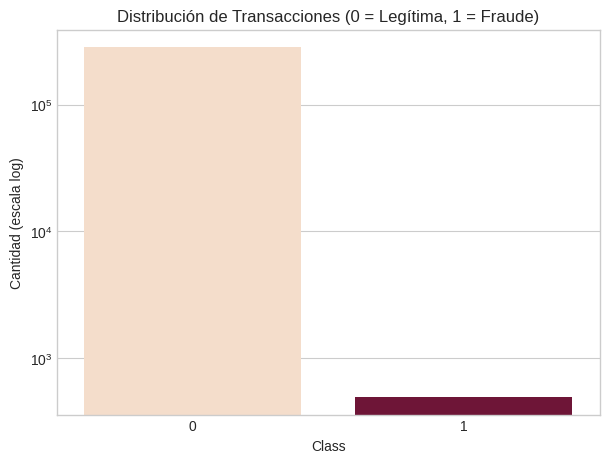

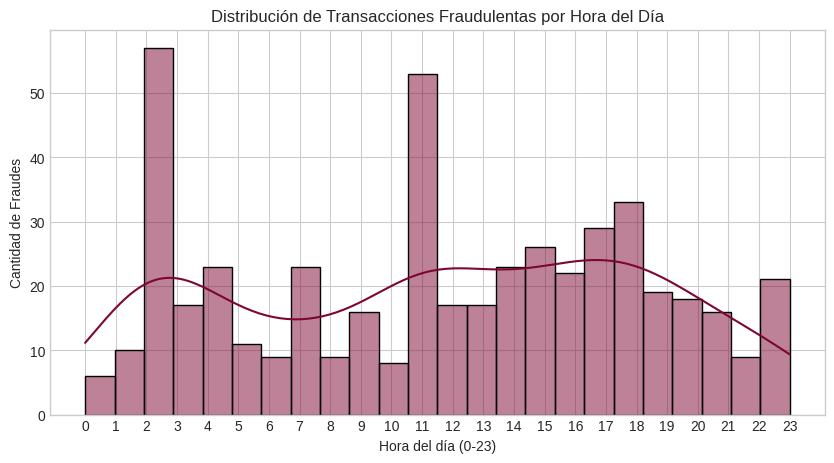

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo
plt.style.use('seaborn-v0_8-whitegrid')

# 1. Carga de datos (ajusta la ruta según la ubicación de tu csv)
# Si el csv está en la raíz y el notebook en 01_notebook, la ruta es '../creditcard.csv'
df = pd.read_csv('/home/kat/Documentos/programacion_avanzada/bank/archive/creditcard.csv')

# 2. Análisis Exploratorio inicial
print("Forma del dataset:", df.shape)
print("Valores nulos totales:", df.isnull().sum().sum())

# 3. Transformación: Crear franja horaria a partir de 'Time' (segundos desde la primera transacción)
df['Hour'] = (df['Time'] // 3600) % 24

# 4. Distribución de la variable objetivo (Class: 0 = Legítima, 1 = Fraude)
conteo_clases = df['Class'].value_counts()
print("\nDistribución de clases:\n", conteo_clases)
print(f"Porcentaje de fraude: {conteo_clases[1] / len(df) * 100:.3f}%")

# Gráfico 1: Distribución de las clases (Escala logarítmica)
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Class', hue='Class', palette=['#FBDCC4', '#7D0633'], legend=False)
plt.title('Distribución de Transacciones (0 = Legítima, 1 = Fraude)')
plt.ylabel('Cantidad (escala log)')
plt.yscale('log') 
plt.show()

# Gráfico 2: Distribución de fraudes por hora
plt.figure(figsize=(10, 5))
sns.histplot(data=df[df['Class'] == 1], x='Hour', bins=24, color='#7D0633', kde=True)
plt.title('Distribución de Transacciones Fraudulentas por Hora del Día')
plt.xticks(range(0, 24))
plt.xlabel('Hora del día (0-23)')
plt.ylabel('Cantidad de Fraudes')
plt.show()

In [3]:
# ==========================================
# MÓDULO 1: PROBABILIDAD Y TEOREMA DE BAYES
# ==========================================

# 1. P(Fraude) Marginal
p_fraude = len(df[df['Class'] == 1]) / len(df)
p_legitima = 1 - p_fraude
print(f"1. Probabilidad marginal P(Fraude): {p_fraude:.6f} ({p_fraude*100:.3f}%)")

# 2. P(Fraude | Monto Alto)
# Definiremos "monto alto" como transacciones mayores a 100 (ajustable)
umbral_monto = 100
monto_alto = df[df['Amount'] > umbral_monto]
p_fraude_dado_monto = len(monto_alto[monto_alto['Class'] == 1]) / len(monto_alto)
print(f"2. P(Fraude | Monto > {umbral_monto}): {p_fraude_dado_monto:.6f} ({p_fraude_dado_monto*100:.3f}%)")

# 3. P(Fraude | Franja Horaria)
# En tu gráfica vimos un pico importante de fraudes alrededor de la hora 2 de la madrugada
hora_pico = 2
transacciones_hora = df[df['Hour'] == hora_pico]
p_fraude_dado_hora = len(transacciones_hora[transacciones_hora['Class'] == 1]) / len(transacciones_hora)
print(f"3. P(Fraude | Hora == {hora_pico}): {p_fraude_dado_hora:.6f} ({p_fraude_dado_hora*100:.3f}%)")

# 4. Teorema de Bayes y Paradoja de la Tasa Base
# Supongamos una regla o modelo antifraude con las siguientes métricas:
sensibilidad = 0.85  # P(Alerta | Fraude): Detecta el 85% de los fraudes reales
especificidad = 0.95 # P(No Alerta | Legítima): Clasifica bien el 95% de las legítimas
p_alerta_dado_legitima = 1 - especificidad # 5% de falsos positivos

# Probabilidad Total de generar una alerta P(Alerta)
p_alerta = (sensibilidad * p_fraude) + (p_alerta_dado_legitima * p_legitima)

# Teorema de Bayes: P(Fraude | Alerta)
p_fraude_dado_alerta = (sensibilidad * p_fraude) / p_alerta

print("\n--- APLICACIÓN DEL TEOREMA DE BAYES ---")
print(f"Sensibilidad: {sensibilidad*100}% | Especificidad: {especificidad*100}%")
print(f"4. P(Fraude | Alerta) = {p_fraude_dado_alerta:.4f} ({p_fraude_dado_alerta*100:.2f}%)")

print("\nExplicación de la Paradoja de la Tasa Base:")
print("A pesar de tener un modelo con 95% de especificidad y 85% de sensibilidad, si salta una alerta, ")
print(f"la probabilidad real de que sea un fraude es solo del {p_fraude_dado_alerta*100:.2f}%. Esto ocurre porque ")
print("la tasa base de fraude es extremadamente baja (0.173%). La inmensa mayoría de las transacciones son ")
print("legítimas, por lo que ese pequeño 5% de falsos positivos inunda el sistema de alertas falsas.")

1. Probabilidad marginal P(Fraude): 0.001727 (0.173%)
2. P(Fraude | Monto > 100): 0.002301 (0.230%)
3. P(Fraude | Hora == 2): 0.017127 (1.713%)

--- APLICACIÓN DEL TEOREMA DE BAYES ---
Sensibilidad: 85.0% | Especificidad: 95.0%
4. P(Fraude | Alerta) = 0.0286 (2.86%)

Explicación de la Paradoja de la Tasa Base:
A pesar de tener un modelo con 95% de especificidad y 85% de sensibilidad, si salta una alerta, 
la probabilidad real de que sea un fraude es solo del 2.86%. Esto ocurre porque 
la tasa base de fraude es extremadamente baja (0.173%). La inmensa mayoría de las transacciones son 
legítimas, por lo que ese pequeño 5% de falsos positivos inunda el sistema de alertas falsas.


--- MOMENTOS ESTADÍSTICOS DEL MONTO ('AMOUNT') POR CLASE ---

Legítima (0):
 Media (Esperanza empírica): 88.2910
 Varianza: 62552.5572
 Asimetría (Skewness): 17.0031
 Curtosis: 846.7370

Fraude (1):
 Media (Esperanza empírica): 122.2113
 Varianza: 65886.3105
 Asimetría (Skewness): 3.7545
 Curtosis: 17.7457

--- AJUSTE DE DISTRIBUCIÓN Y PÉRDIDA ESPERADA ---
Distribución ajustada: Log-Normal
Parámetros: shape=2.5543, scale=14.1624
Pérdida esperada teórica (E[X]): 369.7312


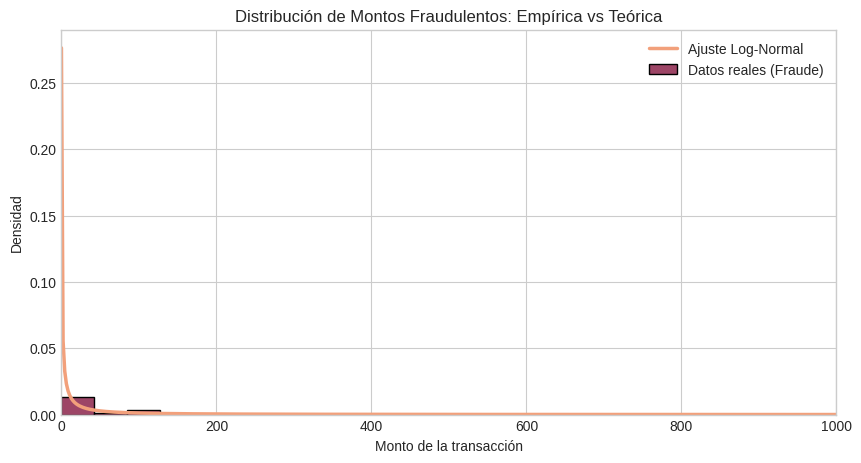

In [4]:
import scipy.stats as stats

# ==========================================
# MÓDULO 2: VARIABLES ALEATORIAS Y MOMENTOS
# ==========================================

print("--- MOMENTOS ESTADÍSTICOS DEL MONTO ('AMOUNT') POR CLASE ---")
for c in [0, 1]:
    clase_nombre = "Legítima (0)" if c == 0 else "Fraude (1)"
    datos_monto = df[df['Class'] == c]['Amount']
    
    print(f"\n{clase_nombre}:")
    print(f" Media (Esperanza empírica): {datos_monto.mean():.4f}")
    print(f" Varianza: {datos_monto.var():.4f}")
    print(f" Asimetría (Skewness): {datos_monto.skew():.4f}")
    print(f" Curtosis: {datos_monto.kurt():.4f}")

# Filtrar los montos de fraude mayores a 0 (el logaritmo de 0 no está definido)
montos_fraude = df[(df['Class'] == 1) & (df['Amount'] > 0)]['Amount']

# Ajuste de distribución Log-Normal
# floc=0 fuerza a que el límite inferior de la distribución sea 0
shape, loc, scale = stats.lognorm.fit(montos_fraude, floc=0)

# La pérdida esperada es la esperanza matemática E[X] del modelo teórico ajustado
perdida_esperada_teorica = stats.lognorm.mean(shape, loc=loc, scale=scale)

print("\n--- AJUSTE DE DISTRIBUCIÓN Y PÉRDIDA ESPERADA ---")
print(f"Distribución ajustada: Log-Normal")
print(f"Parámetros: shape={shape:.4f}, scale={scale:.4f}")
print(f"Pérdida esperada teórica (E[X]): {perdida_esperada_teorica:.4f}")

# Gráfico: Datos reales vs Ajuste Log-Normal
plt.figure(figsize=(10, 5))

# Histograma de densidad de los datos reales (Garnet Red)
sns.histplot(montos_fraude, bins=50, stat='density', color='#7D0633', label='Datos reales (Fraude)')

# Línea de la distribución teórica Log-Normal (Sunset Peach)
x_rango = np.linspace(montos_fraude.min(), montos_fraude.max(), 1000)
pdf_teorica = stats.lognorm.pdf(x_rango, shape, loc=loc, scale=scale)
plt.plot(x_rango, pdf_teorica, color='#F2A07B', linewidth=2.5, label='Ajuste Log-Normal')

plt.title('Distribución de Montos Fraudulentos: Empírica vs Teórica')
plt.xlabel('Monto de la transacción')
plt.ylabel('Densidad')
# Recortamos el eje X a 1000 para visualizar bien la concentración de la curva debido a la asimetría extrema
plt.xlim(0, 1000)
plt.legend()
plt.show()

--- PRUEBA CHI-CUADRADO DE INDEPENDENCIA ---
Estadístico Chi-cuadrado: 674.4434
Valor p: 1.0660e-127
Conclusión: Rechazamos la hipótesis nula. Existe dependencia estadística entre la hora del día y la probabilidad de fraude.

--- MATRICES DE CORRELACIÓN ---


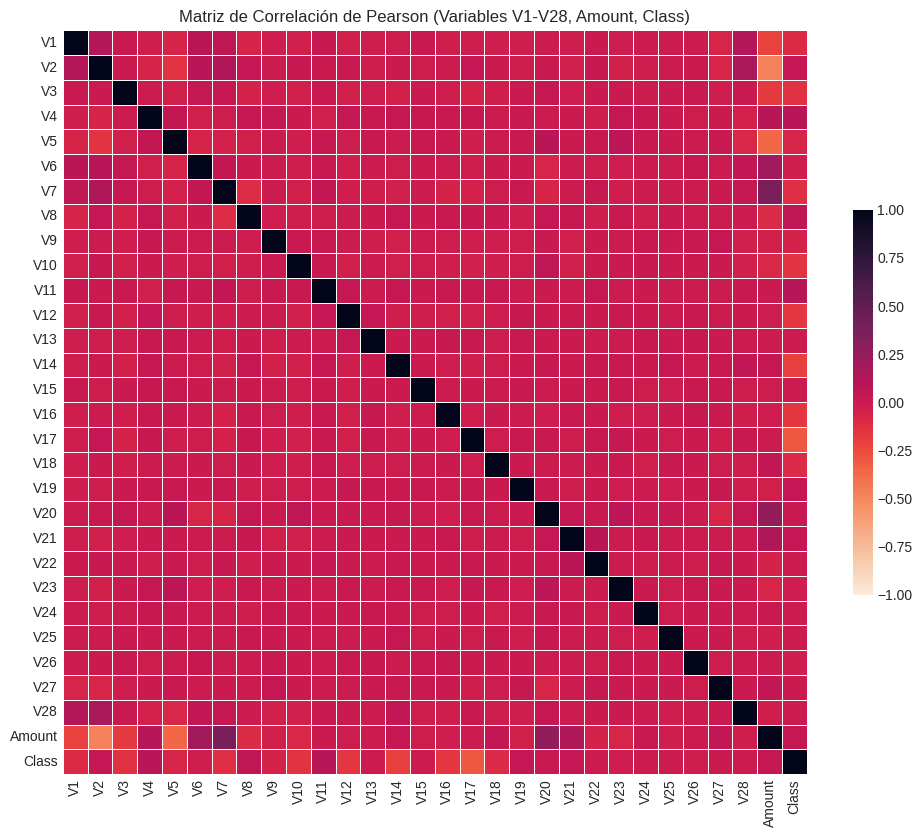


Top 5 variables más correlacionadas con Fraude (Pearson):
V17    0.299371
V14    0.205613
V12    0.160534
V16    0.158727
V10    0.145086
Name: Class, dtype: float64


In [5]:
# ==========================================
# MÓDULO 3: INDEPENDENCIA Y CORRELACIÓN
# ==========================================
from scipy.stats import chi2_contingency

# 1. Prueba Chi-cuadrado: Franja horaria vs Fraude
print("--- PRUEBA CHI-CUADRADO DE INDEPENDENCIA ---")
# Crear tabla de contingencia
tabla_contingencia = pd.crosstab(df['Hour'], df['Class'])
chi2, p_valor, dof, esperados = chi2_contingency(tabla_contingencia)

print(f"Estadístico Chi-cuadrado: {chi2:.4f}")
print(f"Valor p: {p_valor:.4e}")
if p_valor < 0.05:
    print("Conclusión: Rechazamos la hipótesis nula. Existe dependencia estadística entre la hora del día y la probabilidad de fraude.")
else:
    print("Conclusión: No podemos rechazar la hipótesis nula. Son independientes.")

# 2. Correlaciones Pearson y Spearman (Muestra aleatoria por rendimiento)
print("\n--- MATRICES DE CORRELACIÓN ---")
# Usamos una muestra porque calcular Spearman en 284k registros es muy pesado
df_muestra = df.sample(n=10000, random_state=42)

# Excluimos 'Time' y 'Hour' para enfocarnos en las V, Amount y Class
columnas_corr = [f'V{i}' for i in range(1, 29)] + ['Amount', 'Class']
df_corr = df_muestra[columnas_corr]

corr_pearson = df_corr.corr(method='pearson')
corr_spearman = df_corr.corr(method='spearman')

# Gráfico de Correlación de Pearson
plt.figure(figsize=(12, 10))
sns.heatmap(corr_pearson, cmap='rocket_r', center=0, vmin=-1, vmax=1, 
            square=True, linewidths=.5, cbar_kws={"shrink": .5})
plt.title('Matriz de Correlación de Pearson (Variables V1-V28, Amount, Class)')
plt.show()

# 3. Extraer las variables más correlacionadas con el fraude (Class)
print("\nTop 5 variables más correlacionadas con Fraude (Pearson):")
correlaciones_clase = corr_pearson['Class'].drop('Class')
print(correlaciones_clase.abs().sort_values(ascending=False).head(5))

--- 1. REGRESIÓN LOGÍSTICA (Detección de Fraude) ---
Reporte de Clasificación:
               precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962



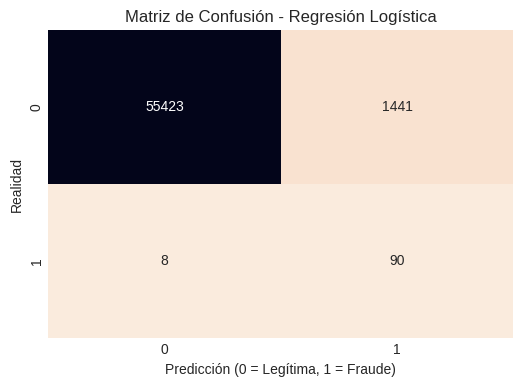


--- 2. REGRESIÓN DE POISSON (Frecuencia de Fraudes por Hora) ---
                 Generalized Linear Model Regression Results                  
Dep. Variable:          ConteoFraudes   No. Observations:                   24
Model:                            GLM   Df Residuals:                       22
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -134.60
Date:                Thu, 29 Oct 2026   Deviance:                       156.11
Time:                        19:47:19   Pearson chi2:                     184.
No. Iterations:                     4   Pseudo R-squ. (CS):           0.009121
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------

In [6]:
# ==========================================
# MÓDULO 4: REGRESIÓN LOGÍSTICA Y POISSON
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import statsmodels.api as sm

print("--- 1. REGRESIÓN LOGÍSTICA (Detección de Fraude) ---")
# Separar características (X) y objetivo (y). Excluimos 'Time' y 'Hour' para usar solo las V1-V28 y Amount
X = df.drop(columns=['Class', 'Time', 'Hour'])
y = df['Class']

# División de datos (80% entrenamiento, 20% prueba)
# stratify=y asegura que la misma proporción mínima de fraudes quede en ambos conjuntos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Entrenar modelo (class_weight='balanced' penaliza fuertemente los errores en la clase minoritaria)
modelo_logistico = LogisticRegression(class_weight='balanced', max_iter=1000)
modelo_logistico.fit(X_train, y_train)

y_pred = modelo_logistico.predict(X_test)
print("Reporte de Clasificación:\n", classification_report(y_test, y_pred))

# Gráfico de Matriz de Confusión
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='rocket_r', cbar=False)
plt.title('Matriz de Confusión - Regresión Logística')
plt.xlabel('Predicción (0 = Legítima, 1 = Fraude)')
plt.ylabel('Realidad')
plt.show()

print("\n--- 2. REGRESIÓN DE POISSON (Frecuencia de Fraudes por Hora) ---")
# Agrupar la cantidad de fraudes por hora
fraudes_por_hora = df[df['Class'] == 1].groupby('Hour').size().reset_index(name='ConteoFraudes')

# Variable independiente (X: Hora) y dependiente (y: Conteo de fraudes)
X_poisson = sm.add_constant(fraudes_por_hora['Hour']) # statsmodels requiere agregar la constante manualmente
y_poisson = fraudes_por_hora['ConteoFraudes']

# Entrenar modelo Poisson
modelo_poisson = sm.GLM(y_poisson, X_poisson, family=sm.families.Poisson()).fit()
print(modelo_poisson.summary())

In [8]:
# ==========================================
# MÓDULO 5: SIMILITUD Y DISTANCIA
# ==========================================
import distancias
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("--- PRUEBAS DE SIMILITUD CONTRA PERFIL FRAUDULENTO ---")

# 1. Extraer variables numéricas
features = df.drop(['Class', 'Time', 'Hour'], axis=1)

# 2. ESTANDARIZAR LOS DATOS (Elimina el sesgo de la variable Amount)
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)
features_scaled = pd.DataFrame(features_scaled, columns=features.columns)

# 3. Crear el "Perfil de Fraude" con los datos escalados
perfil_fraude = features_scaled[df['Class'] == 1].mean().values

# 4. Tomar transacciones de prueba
tx_legitima = features_scaled[df['Class'] == 0].iloc[0].values
tx_fraude = features_scaled[df['Class'] == 1].iloc[0].values

# 5. Calcular distancias usando tu módulo externo
dist_legitima = distancias.distancia_euclidiana(tx_legitima, perfil_fraude)
dist_fraude = distancias.distancia_euclidiana(tx_fraude, perfil_fraude)

sim_legitima = distancias.similitud_coseno(tx_legitima, perfil_fraude)
sim_fraude = distancias.similitud_coseno(tx_fraude, perfil_fraude)

print(">> Evaluando transacción LEGÍTIMA:")
print(f"Distancia Euclidiana al perfil de fraude: {dist_legitima:.4f}")
print(f"Similitud Coseno al perfil de fraude: {sim_legitima:.4f}\n")

print(">> Evaluando transacción FRAUDULENTA:")
print(f"Distancia Euclidiana al perfil de fraude: {dist_fraude:.4f}")
print(f"Similitud Coseno al perfil de fraude: {sim_fraude:.4f}")

--- PRUEBAS DE SIMILITUD CONTRA PERFIL FRAUDULENTO ---
>> Evaluando transacción LEGÍTIMA:
Distancia Euclidiana al perfil de fraude: 17.6231
Similitud Coseno al perfil de fraude: 0.0089

>> Evaluando transacción FRAUDULENTA:
Distancia Euclidiana al perfil de fraude: 9.6960
Similitud Coseno al perfil de fraude: 0.9117


--- REDUCCIÓN DE DIMENSIONES A 2D PARA VISUALIZACIÓN ---


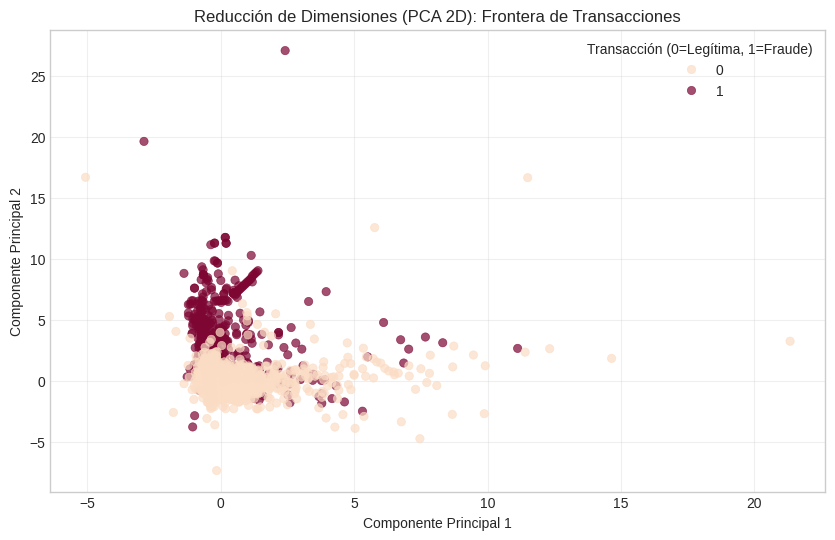

Varianza explicada por C1: 6.75%
Varianza explicada por C2: 3.45%
Varianza total conservada en el plano 2D: 10.20%


In [9]:
# ==========================================
# MÓDULO 6: REDUCCIÓN DE DIMENSIONES (PCA)
# ==========================================
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("--- REDUCCIÓN DE DIMENSIONES A 2D PARA VISUALIZACIÓN ---")

# 1. Tomamos las características estandarizadas del Módulo 5 (features_scaled)
pca_2d = PCA(n_components=2)
componentes_2d = pca_2d.fit_transform(features_scaled)

# 2. Creamos un DataFrame con los nuevos vectores 2D
df_pca = pd.DataFrame(data=componentes_2d, columns=['Componente_1', 'Componente_2'])
df_pca['Class'] = df['Class'].values 

# 3. Muestreo estratégico para la gráfica
# Tomamos TODOS los fraudes y una muestra aleatoria de 3,000 legítimas.
# (Si graficamos los 284,807 puntos, las transacciones legítimas taparán visualmente a los fraudes).
fraudes_pca = df_pca[df_pca['Class'] == 1]
legitimas_pca = df_pca[df_pca['Class'] == 0].sample(n=3000, random_state=42)
df_pca_muestra = pd.concat([fraudes_pca, legitimas_pca])

# 4. Graficar el espacio de baja dimensión
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Componente_1', y='Componente_2', 
    hue='Class', 
    data=df_pca_muestra, 
    palette={0: '#FBDCC4', 1: '#7D0633'}, # Vanilla Peach (Legítimas), Garnet Red (Fraudes)
    alpha=0.7, 
    edgecolor=None
)

plt.title('Reducción de Dimensiones (PCA 2D): Frontera de Transacciones')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(title='Transacción (0=Legítima, 1=Fraude)')
plt.grid(True, alpha=0.3)
plt.show()

# 5. Varianza explicada (Pérdida de información)
varianza = pca_2d.explained_variance_ratio_
print(f"Varianza explicada por C1: {varianza[0]*100:.2f}%")
print(f"Varianza explicada por C2: {varianza[1]*100:.2f}%")
print(f"Varianza total conservada en el plano 2D: {sum(varianza)*100:.2f}%")

--- DEMOSTRACIÓN DE SESGO DE ESCALA (MAGNITUD DE VARIABLES) ---


/tmp/ipykernel_157780/2435413073.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='V1', data=df, ax=axes[0], palette={'0': '#FBDCC4', '1': '#7D0633'})
/tmp/ipykernel_157780/2435413073.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='Amount', data=df, ax=axes[1], palette={'0': '#FBDCC4', '1': '#7D0633'})


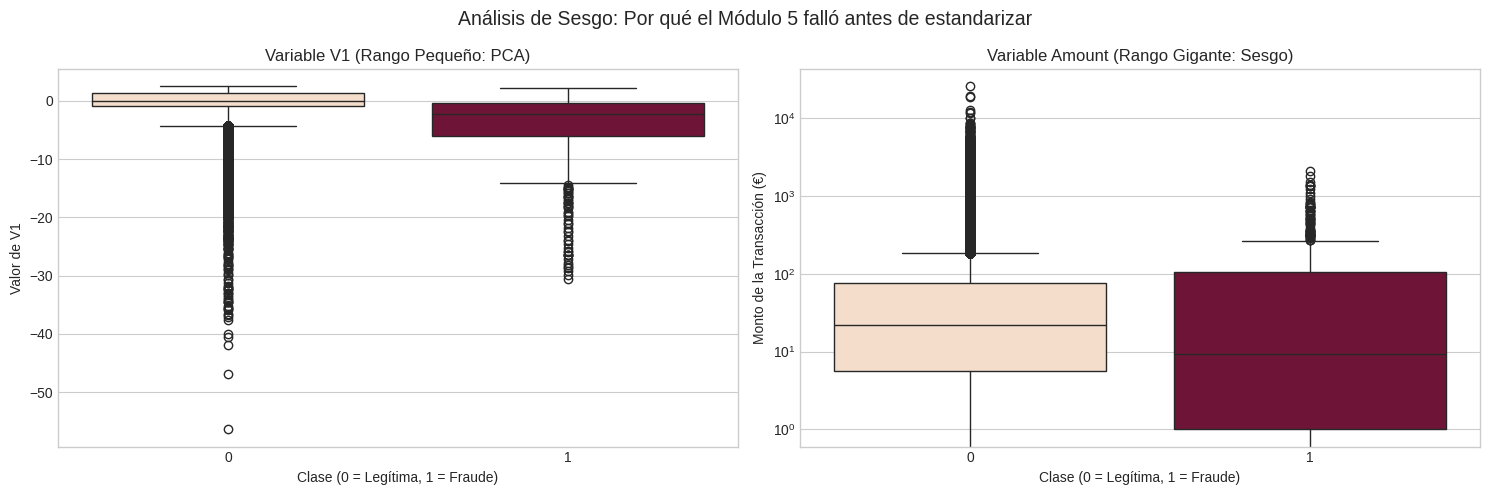

Varianza de V1 (Información de comportamiento): 3.84
Varianza de Amount (Ruido de magnitud): 62560.07
>> El sesgo matemático es de 16,306.59 veces mayor a favor del monto.


In [11]:
# ==========================================
# MÓDULO 8: ANÁLISIS DE SESGOS (SCALE BIAS)
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

print("--- DEMOSTRACIÓN DE SESGO DE ESCALA (MAGNITUD DE VARIABLES) ---")

# 1. Comparamos la variable V1 (transformada) vs Amount (sin transformar)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfica 1: Distribución de V1
sns.boxplot(x='Class', y='V1', data=df, ax=axes[0], palette={'0': '#FBDCC4', '1': '#7D0633'})
axes[0].set_title('Variable V1 (Rango Pequeño: PCA)')
axes[0].set_ylabel('Valor de V1')
axes[0].set_xlabel('Clase (0 = Legítima, 1 = Fraude)')

# Gráfica 2: Distribución de Amount
sns.boxplot(x='Class', y='Amount', data=df, ax=axes[1], palette={'0': '#FBDCC4', '1': '#7D0633'})
axes[1].set_title('Variable Amount (Rango Gigante: Sesgo)')
axes[1].set_ylabel('Monto de la Transacción (€)')
axes[1].set_xlabel('Clase (0 = Legítima, 1 = Fraude)')
axes[1].set_yscale('log') # Usamos escala logarítmica por los valores extremos

plt.suptitle('Análisis de Sesgo: Por qué el Módulo 5 falló antes de estandarizar', fontsize=14)
plt.tight_layout()
plt.show()

# 2. Demostración matemática del peso de la variable
varianza_V1 = df['V1'].var()
varianza_Amount = df['Amount'].var()

print(f"Varianza de V1 (Información de comportamiento): {varianza_V1:.2f}")
print(f"Varianza de Amount (Ruido de magnitud): {varianza_Amount:.2f}")
print(f">> El sesgo matemático es de {varianza_Amount/varianza_V1:,.2f} veces mayor a favor del monto.")

### Conclusión del Módulo 8 (Análisis de Sesgos)
El análisis revela un severo **sesgo de escala**. La variable `Amount` posee una varianza (62,560.07) que es más de 16,300 veces superior a la de variables de comportamiento como `V1` (3.84). Al utilizar algoritmos basados en distancias geométricas (Módulo 5), esta disparidad provoca que la magnitud monetaria abrume y anule la información subyacente de las otras 28 variables. Por ello, la aplicación de `StandardScaler` es un paso obligatorio en el pre-procesamiento para igualar el peso relativo de todas las dimensiones.

In [12]:
# ==========================================
# MÓDULO 9: OPTIMIZACIÓN LINEAL Y COMBINATORIA (SIMPLEX)
# ==========================================
from scipy.optimize import linprog

print("--- OPTIMIZACIÓN DE RECURSOS ANTIFRAUDE (MÉTODO SIMPLEX) ---")

# --- DEFINICIÓN DEL PROBLEMA ---
# Variables de decisión:
# x1: Cantidad de alertas de Alto Riesgo a revisar.
# x2: Cantidad de alertas de Bajo Riesgo a revisar.

# Función Objetivo (A maximizar):
# Cada alerta de Alto Riesgo intercepta en promedio $500 de fraude.
# Cada alerta de Bajo Riesgo intercepta en promedio $100 de fraude.
# En linprog de Scipy siempre se minimiza, así que multiplicamos los coeficientes por -1.
c = [-500, -100]

# Restricciones de Inecuación (A * x <= b):
# Restricción 1 (Tiempo): Revisar una alerta de Alto Riesgo toma 30 min, una de Bajo Riesgo toma 10 min.
#                         El equipo tiene un máximo de 2400 minutos al día (40 horas laborables totales).
# Restricción 2 (Presupuesto operativo): El costo por revisar Alta es $15, por Baja es $5. 
#                                        Presupuesto diario máximo: $1000.
A = [[30, 10], 
     [15,  5]]
b = [2400, 
     1000]

# Límites (Bounds):
# No podemos revisar cantidades negativas de alertas, y el sistema genera 
# como máximo 60 de Alto Riesgo y 150 de Bajo Riesgo al día.
limites = ((0, 60), (0, 150))

# --- RESOLUCIÓN CON SIMPLEX ---
resultado = linprog(c, A_ub=A, b_ub=b, bounds=limites, method='highs')
# ('highs' es el método moderno y robusto en Scipy que reemplazó al simplex clásico obsoleto)

if resultado.success:
    print("\n>> SOLUCIÓN ÓPTIMA ENCONTRADA:")
    print(f"Alertas de Alto Riesgo a revisar al día (x1): {int(round(resultado.x[0]))}")
    print(f"Alertas de Bajo Riesgo a revisar al día (x2): {int(round(resultado.x[1]))}")
    print(f"Fraude total interceptado (Maximización): ${-resultado.fun:,.2f}")
else:
    print("\n>> No se encontró solución factible.")

--- OPTIMIZACIÓN DE RECURSOS ANTIFRAUDE (MÉTODO SIMPLEX) ---

>> SOLUCIÓN ÓPTIMA ENCONTRADA:
Alertas de Alto Riesgo a revisar al día (x1): 60
Alertas de Bajo Riesgo a revisar al día (x2): 20
Fraude total interceptado (Maximización): $32,000.00
